# 1. What counts as progress?

A decline in one measure need not be a decline in another. We will inspect the same swaps using neighboring-order errors, all-pairs inversions, and rank displacement.

Install the repository with `python -m pip install -e '.[examples,dev]'` and select that Python environment. All cells can be rerun: each execution creates a fresh output directory. These are educational experiments with the repaired upstream policies, not a reproduction of a published figure.

In [1]:
%matplotlib inline
from pathlib import Path
import tempfile
import matplotlib.pyplot as plt
from cell_research.experiment import Config, run, replay
Path("outputs").mkdir(exist_ok=True)
output = Path(tempfile.mkdtemp(prefix="progress-", dir="outputs"))

## A four-number counterexample

Predict what happens to each metric when 4 and 1 exchange adjacent positions. An inversion counts every out-of-order pair, even non-neighbors. Rank displacement counts distance from the sorted ranks.

In [2]:
from cell_research.metrics import measure, metric_history
before, after = [2, 4, 1, 3], [2, 1, 4, 3]
print("Before:", before, measure(before))
print("After: ", after, measure(after))
assert measure(after)["adjacent_errors"] > measure(before)["adjacent_errors"]
assert measure(after)["inversions"] < measure(before)["inversions"]

Before: [2, 4, 1, 3] {'adjacent_errors': 1, 'sortedness_percent': 75.0, 'inversions': 3, 'rank_displacement': 6}
After:  [2, 1, 4, 3] {'adjacent_errors': 2, 'sortedness_percent': 50.0, 'inversions': 2, 'rank_displacement': 4}


## Watch the actual sorting policy

Seed 2 selects a trajectory beginning with this swap. This seed illustrates a mechanism; selecting an illustrative trace is not an estimate of its prevalence.

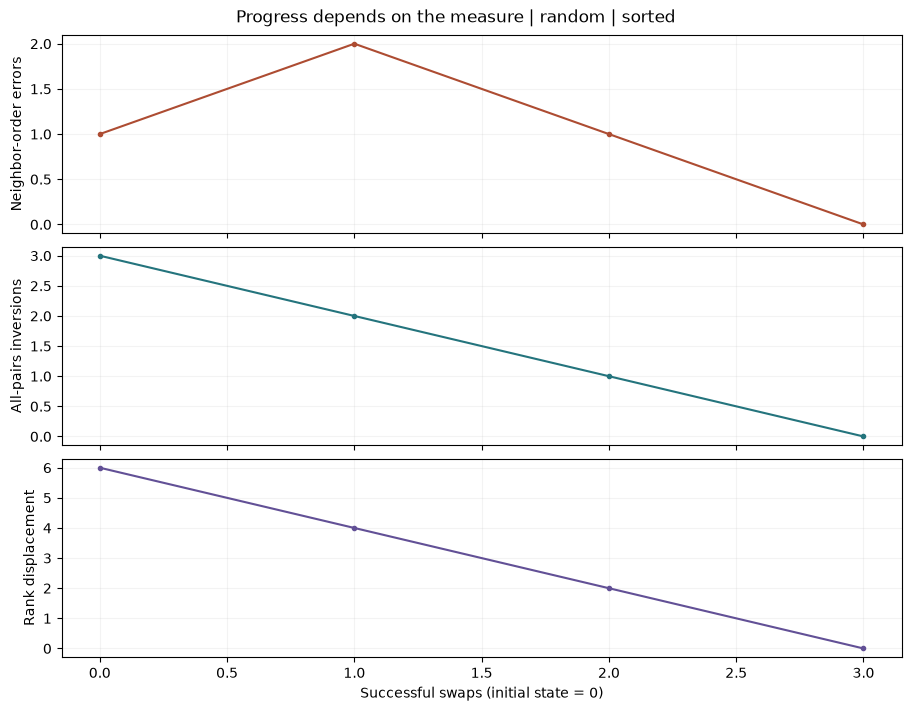

In [3]:
from cell_research.plotting import plot_run, animate_run
from IPython.display import HTML, display
result = run(Config(before, seed=2))
result.save(output / "recording")
fig = plot_run(result)
fig.savefig(output / "progress.png", dpi=150)
plt.show()
animation = animate_run(result)
animation.save(output / "progress.gif", writer="pillow", fps=3)
display(HTML(animation.to_jshtml()))
plt.close(animation._fig)

## An invariant, rather than an interpretation

Every successful bubble swap corrects one adjacent inversion. All-pairs inversions must decrease by exactly one. Neighbor-order errors have no such guarantee. A temporary drop in the paper-style sortedness score therefore does not alone demonstrate planning or delayed gratification.

In [4]:
history = metric_history(result)
assert all(b["inversions"] == a["inversions"] - 1 for a, b in zip(history, history[1:]))
assert replay(output / "recording").summary() == result.summary()
print(result.termination, result.final_values)
print("Verified recording:", output)

sorted [1, 2, 3, 4]
Verified recording: /Users/mhough/Workspace/cell_research/outputs/progress-bxqjy4on


## Explore

Change the values and seed; then try `algorithms=["selection"]`. Does the inversion invariant survive a nonadjacent swap? Try negative values or duplicates. The measurements treat equal-valued cells as interchangeable when computing rank displacement.

The next notebook adds damaged cells. Keep the measurement definitions fixed when comparing conditions.

Sources: [sorting study](https://arxiv.org/abs/2401.05375), [fork methods](../docs/methods.md).